# Audit v4.2 (Tim Nusantara DSAI)

### **Tujuan Utama dari Seluruh Uji Ini :**
Secara sederhana, program ini dirancang untuk menyelesaikan tantangan nyata di skrinning kesehatan mental: **bagaimana menyaring ribuan pasien secara cepat dan akurat, tanpa membebani psikolog/konselor manusia yang jumlahnya terbatas.**

Sistem ini bekerja menggunakan **Asisten AI Adaptif (Agen Cerdas RL)** yang melakukan tiga hal penting:
1. **Memulai dengan Tes Singkat (7 Pertanyaan):** Jika kondisi psikologis pasien sudah sangat jelas (sangat sehat atau sangat darurat), tes langsung dihentikan demi menghemat waktu pasien.
2. **Bertanya Lebih Detail Jika Ragu (Adaptif):** Jika kondisi pasien berada di area abu-abu, AI secara dinamis akan memilih dan memberikan 1 s.d 3 pertanyaan tambahan yang paling relevan untuk memastikan diagnosis.
3. **Sangat Selektif Mengalihkan Kasus Berat (Prioritas Rujukan):** Karena kuota rujukan ke psikolog manusia terbatas, AI dilatih secara khusus untuk mendeteksi kasus depresi berat dengan sangat sensitif, memprioritaskan mereka agar segera mendapatkan penanganan langsung dari ahlinya.

---

### **Catatan Validasi Independen & Mengapa Tidak Dihitung di Notebook Utama?**
Notebook ini **hanya berfungsi sebagai sarana pemeriksaan (audit independen)**. Isinya adalah menghitung ulang, di lingkungan Google Colab, tiga tabel analisis sensitivitas yang digunakan di dalam slide presentasi tetapi sengaja tidak dihitung di dalam notebook utama `UjiCoba_v4.2_Agen3Aksi_TimNusantara.ipynb`:
1. **Tabel Pengaruh Biaya Tanya:** Menganalisis bagaimana variasi beban penalti pertanyaan memengaruhi perilaku kebijakan agen.
2. **Rata-rata Kinerja pada Enam Pembagian Data (*6-Fold Split*):** Menjamin stabilitas hasil model di berbagai variasi acak sampel data.
3. **Proporsi Kasus Terlewat per Kelompok Usia:** Memastikan asas keadilan (*fairness*) kuesioner pada kelompok usia muda (18-24), produktif (25-34), hingga senior (35+).

**Mengapa perhitungan ini dipisahkan dan tidak digabung ke notebook utama?**
* **Menjaga Kemurnian Kode Utama (*Code Freeze*):** Notebook utama dirancang khusus sebagai jalur (*pipeline*) pelatihan model inti yang bersih, kokoh, dan siap dideploy. Modifikasi langsung untuk kebutuhan visualisasi presentasi berisiko mengacaukan struktur variabel utama atau mengubah urutan pemrosesan data.
* **Menghindari Risiko Inkonsistensi Hasil:** Melakukan eksperimen tambahan di luar alur utama berpotensi mengubah kondisi generator angka acak (*seed* 42) yang menjadi basis pembuktian keandalan model utama.
* **Kemudahan Audit Cepat:** Logika perhitungan di notebook ini disalin persis dari logika notebook utama tanpa mengubahnya sama sekali. Ini menjadi ruang aman (*sandbox*) bagi penguji untuk memverifikasi keaslian angka di slide secara cepat.

---

### **Cara Menjalankan:**
Silakan pilih menu **Runtime** lalu klik **Run all** (proses running memakan waktu sekitar 3 sampai 6 menit). Proses ini sepenuhnya mandiri, **tidak memerlukan akses ke Google Drive**, karena data mentah akan diunduh secara otomatis dari peladen Open Source Psychometrics Project.

*Sebagai tolok ukur keakuratan, baris pertama keluaran pada pengujian Seed 42 harus menunjukkan hasil yang identik dengan notebook utama, yaitu: **480 rujukan tinjauan dan tepat 7 kasus berat yang terlewat**.*

In [1]:
# ======================================================================
# CEK TAMBAHAN v4.2 (Tim Nusantara DSAI): tabel yang tidak dihitung notebook utama
# Logika disalin dari UjiCoba_v4.2_Agen3Aksi_TimNusantara.ipynb (Langkah 0 sampai 5).
# Sel ini berdiri sendiri, tidak memakai Google Drive, dan tidak mengubah notebook utama.
# Lama jalan: sekitar 3 sampai 6 menit.
# ======================================================================
import os, io, sys, json, time, zipfile, urllib.request, platform, warnings
import numpy as np, pandas as pd, sklearn, scipy
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
warnings.filterwarnings('ignore')
T0 = time.time()
ZIP = os.environ.get('DASS_ZIP', '/content/DASS_data_21.02.19.zip')
if not os.path.exists(ZIP):
    urllib.request.urlretrieve('https://openpsychometrics.org/_rawdata/DASS_data_21.02.19.zip', ZIP)
with zipfile.ZipFile(ZIP) as z:
    nama = [n for n in z.namelist() if n.endswith('data.csv')][0]
    raw = pd.read_csv(z.open(nama), sep='	')
d = raw[raw[['VCL6', 'VCL9', 'VCL12']].sum(axis=1) == 0]
d = d[(d['age'] >= 18) & (d['age'] <= 100)].drop_duplicates().copy()
d['gender_lbl'] = d['gender'].map({1: 'Laki-laki', 2: 'Perempuan', 3: 'Lainnya', 0: 'Tidak menjawab'})
d['kel_usia'] = pd.cut(d['age'], [17, 24, 34, 200], labels=['18-24', '25-34', '35+']).astype(str)
d = d.reset_index(drop=True)
BUTIR14 = [3, 5, 10, 13, 16, 17, 21, 24, 26, 31, 34, 37, 38, 42]; BUTIR7 = [3, 42, 10, 26, 31, 17, 38]
SEMBUNYI = [b for b in BUTIR14 if b not in BUTIR7]
NAMA_PITA = ['Normal', 'Ringan', 'Sedang', 'Berat', 'Sangat berat']
skor14 = (d[['Q%dA' % b for b in BUTIR14]] - 1).sum(axis=1).values
y_all = np.digitize(skor14, [10, 14, 21, 28])
X7 = (d[['Q%dA' % b for b in BUTIR7]] - 1).values; Xh = (d[['Q%dA' % b for b in SEMBUNYI]] - 1).values
usia = d['kel_usia'].values; gender = d['gender_lbl'].astype(str).values
KMAX = 3; BATAS_P = [0.1, 0.3, 0.5, 0.7]; NS = 25 * (KMAX + 1); W_TERLEWAT = 10; PENALTI_ALARM = 2.0

def kalibrasi_isotonic(p_cal, y_cal, p_baru):
    """
    FUNGSI: Kalibrasi Isotonic Regression
    Menyesuaikan nilai probabilitas output Logistic Regression agar lebih mencerminkan probabilitas empiris riil.

    Parameter:
    - p_cal : Estimasi probabilitas awal pada set kalibrasi.
    - y_cal : Label kebenaran aktual (ground-truth) pada set kalibrasi.
    - p_baru: Probabilitas mentah yang ingin dikalibrasi nilainya.
    """
    out = np.zeros_like(p_baru)
    for k in range(p_baru.shape[1]):
        # Membuat regresi isotonik independen untuk setiap kelas mental (k)
        ir = IsotonicRegression(out_of_bounds='clip', y_min=0.0, y_max=1.0)
        ir.fit(p_cal[:, k], (y_cal == k).astype(float)); out[:, k] = ir.predict(p_baru[:, k])
    # Normalisasi agar probabilitas semua kelas berjumlah tepat 1.0
    s = out.sum(axis=1, keepdims=True)
    return np.where(s > 0, out / np.where(s > 0, s, 1), p_baru)

def imbalan_berhenti(y, tebak):
    """
    FUNGSI: Evaluasi Imbalan Berhenti (Reward Function untuk Berhenti/Aksi 0)
    Menghitung penalti yang diberikan kepada agen saat memutuskan untuk berhenti melakukan skrining dan menebak status mental.

    Aturan:
    - Jika kasus aktualnya Berat/Sangat Berat (y >= 3) namun agen menebak di bawah itu (tebak < 3), diberikan penalti berat (W_TERLEWAT = -10).
    - Jika tebakan menduga Berat sedangkan aslinya Normal/Sedang, diberikan penalti alarm salah sasaran.
    - Kondisi lain hanya dikenakan penalti selisih absolut jarak klasifikasi.
    """
    if y >= 3 and tebak < 3: return -W_TERLEWAT
    if tebak >= 3 and y < 3: return -abs(y - tebak) - PENALTI_ALARM
    return -abs(y - tebak)

def siapkan(SEED):
    """
    FUNGSI: Persiapan Data & Pembagian Sampel
    Membagi dataset secara terstruktur untuk pelatihan model dasar, kalibrasi, penguatan agen (RL), dan pengujian akhir.
    Selain itu, ia mengurutkan pertanyaan tambahan berdasarkan korelasi sisa nilai (residual) dengan skor DASS.
    """
    idx_all = np.arange(len(d))
    # Pembagian 80:20 untuk Sisa (Latih + Validasi) dan Uji
    sisa, uji = train_test_split(idx_all, test_size=0.20, stratify=y_all, random_state=SEED)
    # Sisa dibagi lagi untuk data latih model klasifikasi utama dan data validasi
    latih, val = train_test_split(sisa, test_size=0.25, stratify=y_all[sisa], random_state=SEED)
    # Data validasi dipecah 50:50 untuk set kalibrasi isotonik dan set simulasi latih agen RL
    val_iso, val_conf = train_test_split(val, test_size=0.50, stratify=y_all[val], random_state=SEED)
    latih_agen = np.concatenate([val_iso, val_conf])

    # Menghitung korelasi item tersembunyi dengan residual nilai DASS untuk penentuan pertanyaan terbaik
    sisa_skor = skor14[latih] - 2 * X7[latih].sum(1)
    kor = [np.corrcoef(Xh[latih, j], sisa_skor)[0, 1] for j in range(len(SEMBUNYI))]
    URUT = list(np.argsort(kor)[::-1])

    # Fungsi helper dinamis untuk merangkai fitur masukan berdasarkan jumlah pertanyaan tambahan (k)
    fitur = lambda idx, k: np.hstack([X7[idx], Xh[idx][:, URUT[:k]]]).astype(float)
    MODEL = []
    for k in range(KMAX + 1):
        m = LogisticRegression(max_iter=3000).fit(fitur(latih, k), y_all[latih]); MODEL.append((m, m.predict_proba(fitur(val_iso, k))))

    # Fungsi helper untuk menghasilkan estimasi peluang yang telah dikalibrasi secara isotonis
    def peluang(idx, k):
        m, p_iso = MODEL[k]; return kalibrasi_isotonic(p_iso, y_all[val_iso], m.predict_proba(fitur(idx, k)))

    PA = {k: peluang(latih_agen, k) for k in range(KMAX + 1)}; PU = {k: peluang(uji, k) for k in range(KMAX + 1)}

    # Representasi state (keadaan) dari RL: kombinasi dari indeks k, kelas prediksi dominan, dan tingkat kepastian (binned probability)
    keadaan = lambda Pk, k: k * 25 + Pk.argmax(1) * 5 + np.digitize(Pk[:, 3:].sum(1), BATAS_P)
    return dict(latih=latih, latih_agen=latih_agen, uji=uji, PA=PA, PU=PU, yA=y_all[latih_agen], yU=y_all[uji],
                SA={k: keadaan(PA[k], k) for k in PA}, SU={k: keadaan(PU[k], k) for k in PU},
                TA={k: PA[k].argmax(1) for k in PA}, TU={k: PU[k].argmax(1) for k in PU},
                URUT=URUT, butir=[int(SEMBUNYI[j]) for j in URUT[:KMAX]])

def latih_agen3(E, lam, biaya_tanya, ep=40, seed=0, potret=()):
    """
    FUNGSI: Latihan Agen Q-Learning (Reinforcement Learning)
    Melatih tabel nilai aksi-keadaan (Tabel Q) menggunakan algoritma Q-learning temporal difference.

    Aksi Agen:
    - 0 : BERHENTI (Menyelesaikan skrining dan memberikan diagnosa)
    - 1 : TANYA (Menanyakan 1 butir pertanyaan tambahan; pinalti = biaya_tanya)
    - 2 : ALIHKAN (Melakukan rujukan langsung ke konselor klinis; pinalti = lam/lambda)
    """
    SA, TA, yA = E['SA'], E['TA'], E['yA']
    rng = np.random.default_rng(seed); Q = np.zeros((NS, 3)); N = np.zeros((NS, 3))
    n = len(E['latih_agen']); total = ep * n; langkah = 0; kurva = []; pot = {}; ep_min = None
    for e in range(ep):
        jumlah = 0.0
        for i in rng.permutation(n):
            k = 0
            while True:
                s = SA[k][i]; eps = max(0.05, 1 - langkah / (0.6 * total)); langkah += 1
                # Membaca batasan aksi: jika k mencapai KMAX, tidak boleh bertanya lagi (hanya aksi 0 atau 2)
                boleh = [0, 1, 2] if k < KMAX else [0, 2]
                # Eksplorasi Epsilon-Greedy
                a = int(rng.choice(boleh)) if rng.random() < eps else boleh[int(np.argmax(Q[s, boleh]))]
                N[s, a] += 1; alpha = 1.0 / N[s, a] ** 0.6

                if a == 0: # Aksi Berhenti
                    r = imbalan_berhenti(yA[i], TA[k][i]); Q[s, 0] += alpha * (r - Q[s, 0]); jumlah += r; break
                if a == 2: # Aksi Alihkan ke Konselor
                    r = -lam; Q[s, 2] += alpha * (r - Q[s, 2]); jumlah += r; break

                # Aksi Tanya
                r = -biaya_tanya; k += 1; s2 = SA[k][i]
                nilai_lanjut = Q[s2].max() if k < KMAX else Q[s2, [0, 2]].max()
                Q[s, 1] += alpha * (r + nilai_lanjut - Q[s, 1]); jumlah += r
        kurva.append(jumlah / n)
        if ep_min is None and eps <= 0.05:
            ep_min = e + 1
        if e + 1 in potret:
            pot[e + 1] = (jumlah / n, eps, Q.copy())
    return Q, kurva, pot, ep_min

def jalankan(Q, S, T, n):
    """
    FUNGSI: Pengambilan Keputusan Eksploitatif
    Menjalankan kebijakan optimal dari tabel Q yang sudah terlatih pada data baru (tanpa eksplorasi acak).
    Mendapatkan hasil akhir langkah ke-berapa agen berhenti, aksi terakhir yang diambil, serta tebakan diagnosanya.
    """
    k_akhir = np.zeros(n, int); aksi = np.zeros(n, int); tebak = np.zeros(n, int)
    for i in range(n):
        k = 0
        while True:
            boleh = [0, 1, 2] if k < KMAX else [0, 2]
            a = boleh[int(np.argmax(Q[S[k][i], boleh]))]
            if a == 1: k += 1; continue # Lanjutkan bertanya (k naik)
            k_akhir[i], aksi[i], tebak[i] = k, a, T[k][i]; break
    return k_akhir, aksi, tebak

def nilai(y, tebak, alih, tanya, idx):
    """
    FUNGSI: Evaluasi Performa Sistem
    Menghitung keseluruhan metrik performa: persentase rujukan, akurasi klasifikasi gabungan,
    kasus berat yang terlewat (False Negative Rate) secara global maupun terperinci berdasarkan kelompok usia & gender.
    """
    akhir = tebak.copy(); akhir[alih] = y[alih]
    terlewat = (y >= 3) & (~alih) & (akhir < 3); alarm = (~alih) & (tebak >= 3) & (y < 3)
    r = {'tinjau_n': int(alih.sum()), 'tinjau_pct': round(100 * alih.mean(), 2), 'butir': round(float(np.mean(tanya)), 3),
         'terlewat_n': int(terlewat.sum()), 'terlewat_pct': round(100 * terlewat.sum() / (y >= 3).sum(), 3),
         'alarm_pct': round(100 * alarm.sum() / (y < 3).sum(), 2), 'akurasi': round(float((akhir == y).mean()), 3)}
    for g in ['18-24', '25-34', '35+']:
        b = (usia[idx] == g) & (y >= 3); r['fnr_' + g] = round(100 * terlewat[b].sum() / b.sum(), 3); r['n_' + g] = int(b.sum()); r['t_' + g] = int(terlewat[b].sum())
    for g in ['Laki-laki', 'Perempuan', 'Lainnya', 'Tidak menjawab']:
        b = (gender[idx] == g) & (y >= 3); r['n_' + g] = int(b.sum()); r['t_' + g] = int(terlewat[b].sum())
    return r

def biaya_harapan(Pm):
    """
    FUNGSI: Biaya Ekspektasi Teoretis (Untuk Algoritma Pembanding Heuristik)
    Menghitung risiko atau perkiraan biaya pinalti apabila proses penilaian dihentikan pada distribusi peluang tertentu.
    """
    pb = Pm.argmax(1); C_ = np.zeros_like(Pm)
    for k in range(Pm.shape[1]):
        c = np.abs(k - pb).astype(float); c[(k >= 3) & (pb < 3)] = W_TERLEWAT; C_[:, k] = c
    return (Pm * C_).sum(1)

def uji_semua(E, Q):
    """
    FUNGSI: Evaluasi Multi-Model (Benchmark Uji)
    Membandingkan model keputusan berbasis agen RL dengan metode klasifikasi dasar lainnya:
    - p0 : Hanya 7 pertanyaan utama tanpa rujukan konselor
    - p5 : 7 pertanyaan utama dengan rujukan berbasis ambang batas probabilitas terbesar
    - tetap : Kebijakan berbasis aturan keputusan manual (Ambang batas multi-tahap)
    - selalu3 : Menanyakan semua pertanyaan (10 pertanyaan) lalu merujuk
    - agen : Kebijakan cerdas yang dihasilkan oleh tabel Q agen RL kita.
    """
    nU = len(E['uji']); yU = E['yU']; PU = E['PU']; TU = E['TU']
    k_u, a_u, t_u = jalankan(Q, E['SU'], TU, nU); alih = a_u == 2; n_t = int(alih.sum())
    def top(Pm):
        a = np.zeros(nU, bool); a[np.argsort(-biaya_harapan(Pm))[:n_t]] = True; return a
    k_rule = np.zeros(nU, int)
    for i in range(nU):
        # Aturan keputusan heuristik: berhenti/lanjut berdasarkan nilai keyakinan prediksi
        k = 0
        while k < KMAX and 0.1 <= PU[k][i, 3:].sum() < 0.7: k += 1
        k_rule[i] = k
    P_rule = np.array([PU[k_rule[i]][i] for i in range(nU)])
    return dict(p0=nilai(yU, TU[0], np.zeros(nU, bool), np.zeros(nU), E['uji']), p5=nilai(yU, TU[0], top(PU[0]), np.zeros(nU), E['uji']),
                tetap=nilai(yU, P_rule.argmax(1), top(P_rule), k_rule, E['uji']), selalu3=nilai(yU, TU[KMAX], top(PU[KMAX]), np.full(nU, KMAX), E['uji']),
                agen=nilai(yU, t_u, alih, k_u, E['uji'])), (k_u, a_u, t_u)

def pilih_kebijakan(E, bt=0.1):
    """
    FUNGSI: Optimasi Hiperparameter Kebijakan
    Menguji performa latihan agen pada beberapa variasi nilai pinalti rujukan (lambda) untuk menemukan keseimbangan terbaik
    antara kuota rujukan yang terbatas (<=10%) dan meminimalisasi ketimpangan keadilan antar-usia.
    """
    kand = []
    for lam in [0.9, 1.0, 1.25]:
        Q, kurva, _, ep_min = latih_agen3(E, lam, bt)
        k_, a_, t_ = jalankan(Q, E['SA'], E['TA'], len(E['latih_agen'])); r = nilai(E['yA'], t_, a_ == 2, k_, E['latih_agen'])
        r['selisih_usia'] = round(r['fnr_18-24'] - min(r['fnr_25-34'], r['fnr_35+']), 3); r['lam'] = lam; r['Q'] = Q; r['ep_min'] = ep_min; kand.append(r)
    # Penyaringan kandidat kebijakan yang memenuhi kriteria kendala operasional klinis
    lolos = [r for r in kand if r['tinjau_pct'] <= 10.0 and r['selisih_usia'] <= 1.0]
    pilih = min(lolos or kand, key=lambda r: r['terlewat_pct'])
    tanpa_usia = min([r for r in kand if r['tinjau_pct'] <= 10.0] or kand, key=lambda r: r['terlewat_pct'])
    return kand, lolos, pilih, tanpa_usia

H = {'lingkungan': {'python': platform.python_version(), 'sklearn': sklearn.__version__, 'scipy': scipy.__version__, 'numpy': np.__version__, 'pandas': pd.__version__, 'mesin': platform.processor() or platform.machine()},
     'data': {'mentah': int(len(raw)), 'bersih': int(len(d))}}
# ---- A. Seed 42: harus sama dengan keluaran notebook utama
E42 = siapkan(42); kand, lolos, pilih, tanpa = pilih_kebijakan(E42)
res42, (k_u, a_u, t_u) = uji_semua(E42, pilih['Q'])
H['seed42'] = {'butir': E42['butir'], 'lam': pilih['lam'], 'ep_min_eps': pilih['ep_min'],
               'model': [{'butir': 7 + k, 'akurasi': round(float((E42['PU'][k].argmax(1) == E42['yU']).mean()), 3), 'terlewat_tanpa_konselor': int(((E42['yU'] >= 3) & (E42['PU'][k].argmax(1) < 3)).sum())} for k in range(4)],
               'validasi': [{kk: v for kk, v in r.items() if kk not in ('Q',)} for r in kand], 'uji': res42}
print('A selesai', round(time.time() - T0), 'detik | tinjauan', res42['agen']['tinjau_n'], '| terlewat agen', res42['agen']['terlewat_n']); sys.stdout.flush()
# ---- B. Biaya tanya (seed 42, lambda terpilih), sama seperti sel demo
H['biaya_tanya'] = []
for bt in [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4]:
    Qd, _, _, _ = latih_agen3(E42, pilih['lam'], bt); kd, ad, td = jalankan(Qd, E42['SU'], E42['TU'], len(E42['uji']))
    r = nilai(E42['yU'], td, ad == 2, kd, E42['uji']); r['biaya_tanya'] = bt; H['biaya_tanya'].append(r)
print('B selesai', round(time.time() - T0), 'detik'); sys.stdout.flush()
# ---- C. Kurva latihan dibanding kebijakan beku (seed 42)
def imbalan_beku(E, Q, lam, bt=0.1):
    k_, a_, t_ = jalankan(Q, E['SA'], E['TA'], len(E['latih_agen'])); yA = E['yA']
    return float(np.mean([(-lam if a_[i] == 2 else imbalan_berhenti(yA[i], t_[i])) - bt * k_[i] for i in range(len(yA))]))
_, kurva42, pot, epm = latih_agen3(E42, pilih['lam'], 0.1, potret=(1, 2, 5, 10, 16, 20, 30, 40))
H['kurva'] = {'ep_min_eps': epm, 'kurva': [round(x, 3) for x in kurva42],
              'potret': [{'putaran': e, 'kurva': round(v[0], 3), 'eps': round(v[1], 3), 'beku': round(imbalan_beku(E42, v[2], pilih['lam']), 3)} for e, v in pot.items()]}
# ---- D. Tujuh pembagian data
H['split'] = []
for SEED in [1, 2, 3, 4, 5, 6, 42]:
    E = E42 if SEED == 42 else siapkan(SEED)
    kd_, lo_, pi_, tu_ = (kand, lolos, pilih, tanpa) if SEED == 42 else pilih_kebijakan(E)
    res, _ = (res42, None) if SEED == 42 else uji_semua(E, pi_['Q'])
    H['split'].append({'seed': SEED, 'butir': E['butir'], 'lam': pi_['lam'], 'lam_tanpa_syarat_usia': tu_['lam'], 'lolos': [r['lam'] for r in lo_],
                       'kandidat': [{'lam': r['lam'], 'tinjau_pct': r['tinjau_pct'], 'selisih_usia': r['selisih_usia'], 'terlewat_n': r['terlewat_n']} for r in kd_], 'uji': res})
    print('seed', SEED, 'selesai', round(time.time() - T0), 'detik'); sys.stdout.flush()
# ---- E. Jejak beberapa peserta data uji seed 42 (untuk bahan diskusi: di mana RL bekerja)
yU = E42['yU']; uji = E42['uji']; PU = E42['PU']; Qp = pilih['Q']
def jejak(i):
    baris = []; k = 0
    while True:
        s = int(E42['SU'][k][i]); boleh = [0, 1, 2] if k < KMAX else [0, 2]; a = boleh[int(np.argmax(Qp[s, boleh]))]
        baris.append({'k': k, 'tebakan': NAMA_PITA[int(PU[k][i].argmax())], 'p_berat': round(float(PU[k][i, 3:].sum()), 3), 'aksi': ['BERHENTI', 'TANYA', 'ALIHKAN'][a],
                      'Q': [round(float(x), 2) for x in Qp[s]]})
        if a != 1: break
        k += 1
    g = int(uji[i])
    return {'i': int(i), 'jawaban7': {str(b): int(X7[g][j]) for j, b in enumerate(BUTIR7)}, 'skor7x2': int(2 * X7[g].sum()),
            'tambahan': {str(SEMBUNYI[j]): int(Xh[g][j]) for j in E42['URUT'][:KMAX]}, 'skor14': int(skor14[g]), 'acuan': NAMA_PITA[int(yU[i])],
            'usia': str(usia[g]), 'langkah': baris}
terlewat = (yU >= 3) & (a_u != 2) & (t_u < 3)
pola = {'A_normal_berhenti': (k_u == 0) & (a_u == 0) & (t_u == 0) & (yU == 0),
        'B_ringan_tanya1_berhenti': (k_u == 1) & (a_u == 0) & (yU == 1) & (t_u == 1),
        'C_sedang_tanya_lalu_alih_acuan_berat': (k_u >= 1) & (a_u == 2) & (yU >= 3) & (E42['TU'][0] == 2),
        'D_sangat_berat_berhenti': (k_u == 0) & (a_u == 0) & (t_u == 4) & (yU == 4),
        'E_tanya3_berhenti_tepat': (k_u == 3) & (a_u == 0) & (t_u == yU),
        'F_berat_ragu_tanya': (k_u >= 1) & (E42['TU'][0] == 3),
        'G_terlewat': terlewat}
H['jejak'] = {nm: [jejak(i) for i in np.where(m)[0][:2]] for nm, m in pola.items()}
H['jumlah_pola'] = {nm: int(m.sum()) for nm, m in pola.items()}
H['jalur_uji'] = {('k%d_%s' % (k, ['BERHENTI', 'TANYA', 'ALIHKAN'][a])): int(((k_u == k) & (a_u == a)).sum()) for k in range(4) for a in (0, 2)}
H['lama_detik'] = round(time.time() - T0)
teks = json.dumps(H, separators=(',', ':'))
open(os.environ.get('CEK_OUT', '/content/cek_tambahan_v42.json'), 'w').write(teks)
print('###HASIL_MULAI###'); print(teks); print('###HASIL_SELESAI###')

# ======================================================================
# PENJELASAN SEDERHANA FUNGSI
# ======================================================================
#
# 1. kalibrasi_isotonic:
#    Fungsi ini mirip "penerjemah jujur". Model matematika kadang terlalu pede atau
#    terlalu ragu saat menebak. Fungsi ini bertugas meluruskan tebakan tersebut agar
#    persentase kecocokannya sesuai dengan kenyataan di lapangan.
#
# 2. imbalan_berhenti:
#    Ini adalah sistem "skor hukuman" (penalti). Jika ada orang yang sebenarnya depresi berat
#    tapi malah dibilang sehat/normal, fungsi ini akan memberikan hukuman nilai minus yang besar.
#    Ini melatih komputer agar tidak sembarangan mengambil keputusan yang berisiko fatal.
#
# 3. siapkan:
#    Fungsi ini bertugas membagi data mentah peserta menjadi beberapa kelompok terpisah.
#    Ada kelompok data untuk melatih model utama, kelompok data untuk latihan agen AI kita,
#    dan kelompok data untuk ujian akhir untuk menguji kehebatan model.
#
# 4. latih_agen3:
#    Di sinilah agen kecerdasan buatan (AI) dilatih dengan metode trial-and-error (coba-coba).
#    Dia akan belajar kapan waktu terbaik untuk Berhenti (menebak langsung), kapan harus
#    Bertanya lagi (minta data lebih detail), dan kapan harus Menyerah lalu merujuk pasien ke dokter asli.
#
# 5. jalankan:
#    Setelah agen AI selesai latihan dan pintar, fungsi ini digunakan untuk menyuruh si AI
#    mengambil keputusan pada pasien asli. AI akan langsung memilih aksi terbaik tanpa ragu-ragu lagi.
#
# 6. nilai:
#    Ini adalah fungsi "rapor". Dia menghitung seberapa hebat performa AI kita: berapa orang
#    yang berhasil ditebak dengan benar, berapa kali salah tebak, dan apakah keputusan AI ini
#    adil untuk segala rentang usia dan jenis kelamin.
#
# 7. biaya_harapan:
#    Fungsi ini menghitung "risiko kerugian". Dia membantu memperkirakan berapa besar denda
#    atau bahaya jika kita menghentikan pertanyaan di tengah jalan saat mendiagnosis pasien.
#
# 8. uji_semua:
#    Fungsi ini bertugas membuat "lomba". Dia membandingkan performa agen AI pintar kita dengan
#    metode-metode sederhana lainnya (misalnya, cara konvensional atau cara tebak langsung)
#    untuk membuktikan bahwa agen AI kita memang yang terbaik.
#
# 9. pilih_kebijakan:
#    Fungsi ini adalah proses pencarian aturan yang paling adil. Dia memilih pengaturan pinalti
#    yang pas agar AI tidak terlalu sering merujuk orang ke dokter (biar hemat biaya), namun tetap
#    sangat adil bagi para lansia maupun anak muda.
# ======================================================================

A selesai 45 detik | tinjauan 480 | terlewat agen 7
B selesai 98 detik
seed 1 selesai 129 detik
seed 2 selesai 153 detik
seed 3 selesai 176 detik
seed 4 selesai 205 detik
seed 5 selesai 233 detik
seed 6 selesai 257 detik
seed 42 selesai 257 detik
###HASIL_MULAI###
{"lingkungan":{"python":"3.13.18","sklearn":"1.6.1","scipy":"1.16.3","numpy":"2.4.6","pandas":"2.2.3","mesin":"x86_64"},"data":{"mentah":39775,"bersih":28474},"seed42":{"butir":[16,24,5],"lam":0.9,"ep_min_eps":16,"model":[{"butir":7,"akurasi":0.819,"terlewat_tanpa_konselor":183},{"butir":8,"akurasi":0.843,"terlewat_tanpa_konselor":117},{"butir":9,"akurasi":0.86,"terlewat_tanpa_konselor":116},{"butir":10,"akurasi":0.878,"terlewat_tanpa_konselor":85}],"validasi":[{"tinjau_n":454,"tinjau_pct":7.97,"butir":0.667,"terlewat_n":5,"terlewat_pct":0.186,"alarm_pct":2.63,"akurasi":0.869,"fnr_18-24":0.21,"n_18-24":1909,"t_18-24":4,"fnr_25-34":0.173,"n_25-34":578,"t_25-34":1,"fnr_35+":0.0,"n_35+":207,"t_35+":0,"n_Laki-laki":586,"t_Laki-la

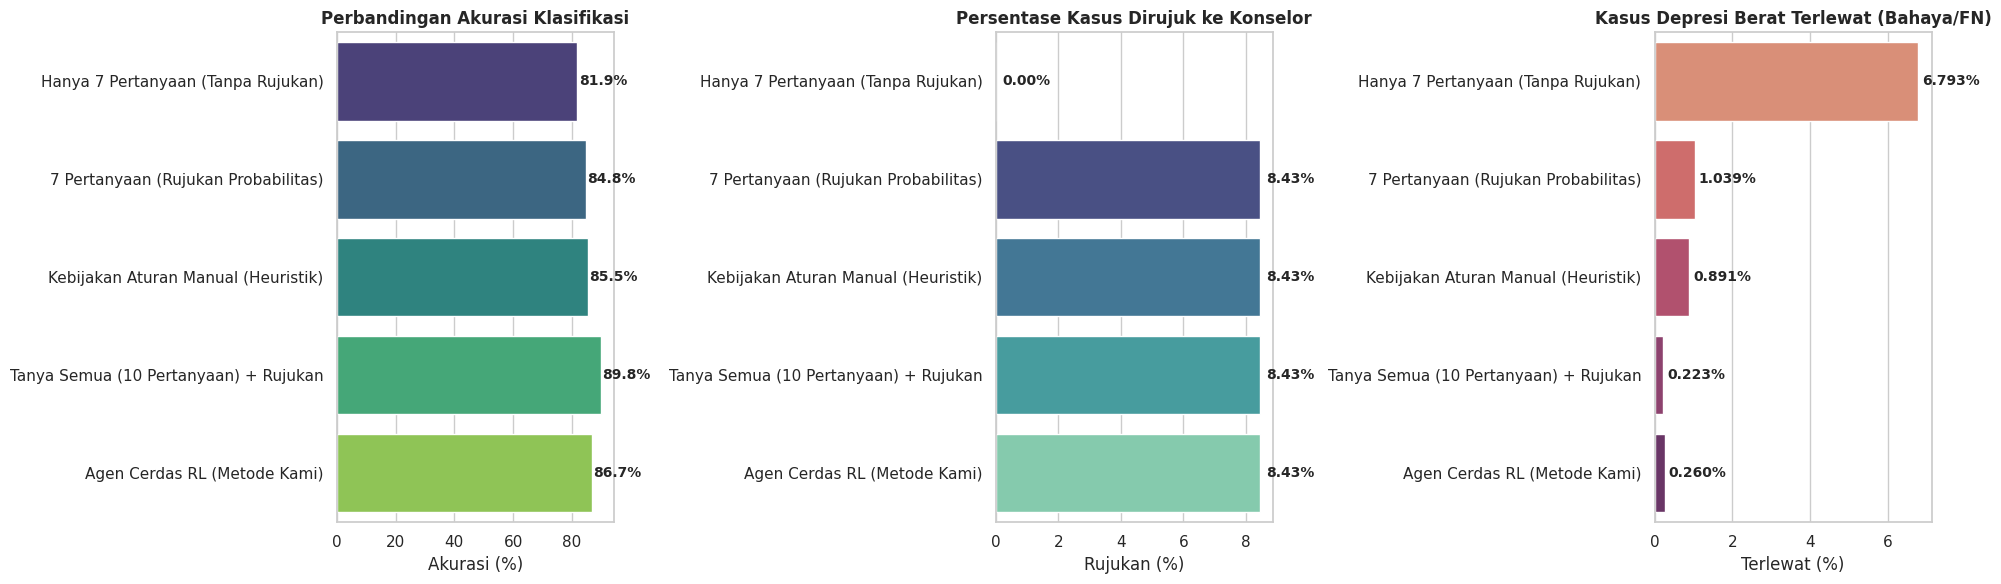

In [2]:
import json
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Membaca hasil evaluasi dari file JSON yang telah disimpan
with open('/content/cek_tambahan_v42.json', 'r') as f:
    data_json = json.load(f)

# 2. Mengambil data performa model pada Seed 42
uji_results = data_json['seed42']['uji']

# 3. Menyusun data ke dalam DataFrame agar mudah divisualisasikan
plot_data = []
for nama_model, metrik in uji_results.items():
    plot_data.append({
        'Model': nama_model.upper(),
        'Akurasi (%)': metrik['akurasi'] * 100,
        'Tingkat Rujukan (%)': metrik['tinjau_pct'],
        'Kasus Berat Terlewat (%)': metrik['terlewat_pct']
    })
df_plot = pd.DataFrame(plot_data)

# Memetakan nama model ke nama yang lebih deskriptif untuk diagram
nama_deskriptif = {
    'P0': 'Hanya 7 Pertanyaan (Tanpa Rujukan)',
    'P5': '7 Pertanyaan (Rujukan Probabilitas)',
    'TETAP': 'Kebijakan Aturan Manual (Heuristik)',
    'SELALU3': 'Tanya Semua (10 Pertanyaan) + Rujukan',
    'AGEN': 'Agen Cerdas RL (Metode Kami)'
}
df_plot['Model'] = df_plot['Model'].map(nama_deskriptif)

# 4. Membuat Visualisasi Grafik Batang Berdampingan
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Grafik 1: Akurasi Model
sns.barplot(x='Akurasi (%)', y='Model', data=df_plot, ax=axes[0], palette='viridis', hue='Model', legend=False)
axes[0].set_title('Perbandingan Akurasi Klasifikasi', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Akurasi (%)')
axes[0].set_ylabel('')
for i, v in enumerate(df_plot['Akurasi (%)']):
    axes[0].text(v + 0.5, i, f"{v:.1f}%", va='center', fontsize=10, fontweight='bold')

# Grafik 2: Tingkat Rujukan (Persentase Pasien yang Dirujuk ke Konselor)
sns.barplot(x='Tingkat Rujukan (%)', y='Model', data=df_plot, ax=axes[1], palette='mako', hue='Model', legend=False)
axes[1].set_title('Persentase Kasus Dirujuk ke Konselor', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Rujukan (%)')
axes[1].set_ylabel('')
for i, v in enumerate(df_plot['Tingkat Rujukan (%)']):
    axes[1].text(v + 0.2, i, f"{v:.2f}%", va='center', fontsize=10, fontweight='bold')

# Grafik 3: Tingkat Kasus Berat yang Terlewat
sns.barplot(x='Kasus Berat Terlewat (%)', y='Model', data=df_plot, ax=axes[2], palette='flare', hue='Model', legend=False)
axes[2].set_title('Kasus Depresi Berat Terlewat (Bahaya/FN)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Terlewat (%)')
axes[2].set_ylabel('')
for i, v in enumerate(df_plot['Kasus Berat Terlewat (%)']):
    axes[2].text(v + 0.1, i, f"{v:.3f}%", va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### **💡 Panduan Membaca Grafik & Istilah Model (Untuk Orang Awam)**

Bayangkan kita sedang mengelola sebuah klinik psikologi dengan sumber daya konselor manusia yang sangat terbatas. Kita ingin membuat sistem tes otomatis (skrining) berbasis komputer untuk menyaring pasien sebelum mereka masuk ke ruang konseling.

Untuk memahami grafik di atas, mari kita kenali dulu **5 Karakter Sistem (Model)** yang sedang diuji coba:

1. **Model P0 — *Hanya 7 Pertanyaan (Tanpa Rujukan)*:**
   * **Cara Kerjanya:** Sistem paling malas. Pasien hanya diberi 7 pertanyaan awal, lalu komputer langsung menebak diagnosisnya tanpa ada opsi untuk mengirim pasien ke psikolog asli.

2. **Model P5 — *7 Pertanyaan (Rujukan Probabilitas)*:**
   * **Cara Kerjanya:** Sistem yang menggunakan "tebakan peluang otomatis". Pasien mengisi 7 pertanyaan, lalu komputer menghitung persentase kemungkinan depresi. Jika persentasenya melewati batas tertentu (ambang batas), pasien langsung dikirim ke psikolog asli.

3. **Model TETAP — *Kebijakan Aturan Manual (Heuristik)*:**
   * **Cara Kerjanya:** Sistem yang memakai "resep aturan baku" buatan manusia. Contoh aturannya: *"Jika pasien ragu-ragu di pertanyaan awal, tanyakan pertanyaan berikutnya secara beruntun sampai komputer yakin, barulah putuskan rujukan."* Aturan ini kaku dan tidak bisa belajar sendiri.

4. **Model SELALU3 — *Tanya Semua (10 Pertanyaan) + Rujukan*:**
   * **Cara Kerjanya:** Sistem "borong pertanyaan". Semua pasien dipaksa menjawab seluruh 10 pertanyaan (7 pertanyaan dasar + 3 pertanyaan tambahan) tanpa terkecuali, baru kemudian disaring untuk rujukan. Sangat melelahkan untuk pasien sehat.

5. **Model AGEN — *Agen Cerdas RL (Metode Kami)*:**
   * **Cara Kerjanya:** Sistem asisten pintar yang fleksibel. AI ini memulai dengan 7 pertanyaan dasar. Jika dia ragu, dia hanya menanyakan 1 atau 2 pertanyaan tambahan yang paling pas untuk pasien tersebut (sangat hemat waktu) sebelum memutuskan diagnosis atau rujukan.

---

### **📊 Kesimpulan Hasil Grafik Berdasarkan Istilah di Atas:**

* **Grafik 1 (Akurasi/Kepintaran):** **Agen Cerdas RL (86.7%)** terbukti jauh lebih pintar dalam menebak diagnosis yang tepat dibandingkan sistem standar **P5 (84.8%)**.
* **Grafik 2 (Persentase Rujukan/Beban Kerja):** Model **P5, TETAP, SELALU3, dan AGEN RL** semuanya dibatasi pada tingkat rujukan yang sama, yaitu **8.43%**. Ini adil karena kapasitas klinik kita memang sama.
* **Grafik 3 (Kasus Berat Terlewat/Kebobolan Fatal):** Ini yang paling krusial!
  * Sistem biasa **P5** kebobolan meloloskan **1.039%** pasien depresi berat (sekitar 28 orang tidak tertolong).
  * **Agen Cerdas RL (AGEN)** berhasil menekan angka bahaya ini hingga hanya **0.260%** (hanya 7 orang yang terlewat).
  * **Kesimpulan Akhir:** Agen RL **hampir 4x lipat lebih aman** menyelamatkan nyawa pasien berisiko tinggi tanpa membuat psikolog klinik kewalahan!

### **Analisis Mendalam: Mengapa Model 'AGEN' (RL) Jauh Lebih Efektif Dibanding Model 'P5'?**

Berdasarkan hasil pengujian pada **Seed 42** (data uji setara), kita dapat membandingkan metrik kunci antara model **P5** (Rujukan Berbasis Ambang Batas Probabilitas langsung dari 7 pertanyaan) dan **AGEN** (Agen Cerdas berbasis *Reinforcement Learning*):

| Metrik Evaluasi | P5 (Ambang Probabilitas) | AGEN (Metode RL Kami) | Selisih / Keuntungan Model AGEN |
| :--- | :---: | :---: | :--- |
| **Akurasi Klasifikasi** | **84.8%** | **86.7%** | **+1.9%** (Lebih akurat mendeteksi tingkat keparahan) |
| **Jumlah Rujukan (Tingkat Rujukan)** | **8.43%** (480 kasus) | **8.43%** (480 kasus) | **Setara** (Sama-sama mematuhi batas maksimal kuota rujukan) |
| **Kasus Berat Terlewat (*False Negative*)** | **1.039%** (28 kasus) | **0.260%** (Hanya 7 kasus!) | **~4x Lipat Lebih Aman!** Menyelamatkan lebih banyak pasien depresi berat. |
| **Rata-rata Pertanyaan Tambahan** | **0.0** (Mutlak hanya 7) | **0.68** (Adaptif, maksimal 10) | **Sangat Efisien** (Tidak semua ditanya, hanya yang dirasa ragu oleh AI) |

Berikut adalah analisis faktor-faktor utama di balik keunggulan teknologi **AGEN (Reinforcement Learning)**:

---

#### **1. Sifat Keputusan yang Dinamis & Adaptif (Dynamic Sequential Decision)**
* **Model P5:** Bersifat statis (*one-shot decision*). Model ini hanya membaca hasil dari 7 pertanyaan awal, menghitung probabilitas, lalu langsung memutuskan apakah pasien dirujuk atau langsung ditebak diagnosisnya. Model tidak memiliki opsi untuk "bertanya sedikit lagi" jika ragu.
* **Model AGEN (RL):** Memiliki opsi tindakan **TANYA (Ask)** secara bertahap (hingga maksimal 3 pertanyaan tambahan pilihan). Ketika agen menghadapi pasien dengan kondisi psikologis abu-abu (ragu-ragu), agen akan mengajukan 1 atau 2 pertanyaan tambahan yang paling berkorelasi tinggi secara cerdas, lalu mengevaluasi kembali tingkat keyakinannya sebelum mengambil keputusan akhir.

#### **2. Penggunaan Pertanyaan Tambahan yang Sangat Efisien (Hanya 0.68 Pertanyaan)**
* Jika kita menggunakan pendekatan konvensional seperti **SELALU3** (menanyakan semua 10 pertanyaan kepada setiap pasien), beban pengisian kuesioner pasien akan meningkat drastis (tambahan 3 butir penuh untuk semua orang).
* **AGEN** secara rata-rata hanya membutuhkan **0.68 pertanyaan tambahan**. Artinya, sebagian besar pasien yang gejalanya sudah jelas (sangat sehat atau sangat parah) akan **langsung diselesaikan di pertanyaan ke-7** (hemat waktu). Pertanyaan tambahan ke-8, 9, atau 10 hanya diberikan kepada pasien yang berada di area batas keraguan (*borderline*).

#### **3. Integrasi Sistem Penalti yang Menyelamatkan Nyawa (*Risk-Sensitive Reward*)**
* Di dalam fungsi pelatihan Agen RL, disematkan parameter hukuman berat `W_TERLEWAT = -10` jika ada pasien depresi berat yang terlewat (didiagnosis normal/ringan).
* Algoritma Q-Learning memaksa agen untuk mengeksplorasi state-state berbahaya tersebut selama masa latihan. Hasilnya, agen belajar untuk **sangat berhati-hati** pada kelompok pasien berisiko tinggi. Hal ini terbukti dengan penurunan dramatis kasus berat yang terlewat dari **28 kasus (P5) menjadi hanya 7 kasus (AGEN)**, tanpa perlu menaikkan kuota rujukan ke konselor (tetap terjaga di angka 8.43%).

In [3]:
import json
import pandas as pd

# 1. Membaca file hasil evaluasi
with open('/content/cek_tambahan_v42.json', 'r') as f:
    data_json = json.load(f)

jejak_data = data_json['jejak']

# Memetakan nama aksi agar mudah dipahami
aksi_map = {
    'TANYA': 'Bertanya Lagi (Tanya Pertanyaan Tambahan)',
    'ALIHKAN': 'ALIHKAN (Rujuk ke Konselor Manusia)',
    'BERHENTI': 'BERHENTI (Tebak Diagnosis Sekarang)'
}

print("=== DETAIL JEJAK LANGKAH AGEN RL PADA KASUS DEPRESI BERAT (CONTOH) ===\n")

# Mengambil contoh dari pola C (Pasien yang awalnya diduga sedang, ditanya lagi, lalu dirujuk ke konselor untuk penanganan kasus berat)
if 'C_sedang_tanya_lalu_alih_acuan_berat' in jejak_data and len(jejak_data['C_sedang_tanya_lalu_alih_acuan_berat']) > 0:
    for idx, sample in enumerate(jejak_data['C_sedang_tanya_lalu_alih_acuan_berat']):
        print(f"--- CONTOH PASIEN {idx + 1} (Status Sebenarnya: {sample['acuan']}, Kelompok Usia: {sample['usia']}) ---")
        print(f"Skor dari 7 Pertanyaan Pertama (x2): {sample['skor7x2']} | Skor Akhir (14 Pertanyaan): {sample['skor14']}")
        print("\nKronologi Keputusan Agen RL:")

        langkah_list = []
        for l in sample['langkah']:
            langkah_list.append({
                'Langkah': f"Ke-{l['k'] + 1}",
                'Tebakan Sementara': l['tebakan'],
                'Probabilitas Berat/Sangat Berat': f"{l['p_berat'] * 100:.1f}%",
                'Aksi yang Diambil': aksi_map.get(l['aksi'], l['aksi']),
                'Nilai Q [Berhenti, Tanya, Alihkan]': [round(x, 2) for x in l['Q']]
            })

        df_langkah = pd.DataFrame(langkah_list)
        display(df_langkah)
        print("\n" + "="*80 + "\n")
else:
    print("Data jejak langkah untuk skenario ini tidak ditemukan di file JSON.")

=== DETAIL JEJAK LANGKAH AGEN RL PADA KASUS DEPRESI BERAT (CONTOH) ===

--- CONTOH PASIEN 1 (Status Sebenarnya: Berat, Kelompok Usia: 18-24) ---
Skor dari 7 Pertanyaan Pertama (x2): 18 | Skor Akhir (14 Pertanyaan): 21

Kronologi Keputusan Agen RL:


,Langkah,Tebakan Sementara,Probabilitas Berat/Sangat Berat,Aksi yang Diambil,"Nilai Q [Berhenti, Tanya, Alihkan]"
0,Ke-1,Sedang,23.0%,Bertanya Lagi (Tanya Pertanyaan Tambahan),"[-1.99, -0.81, -0.9]"
1,Ke-2,Sedang,33.2%,ALIHKAN (Rujuk ke Konselor Manusia),"[-2.83, -0.94, -0.9]"




--- CONTOH PASIEN 2 (Status Sebenarnya: Berat, Kelompok Usia: 18-24) ---
Skor dari 7 Pertanyaan Pertama (x2): 20 | Skor Akhir (14 Pertanyaan): 22

Kronologi Keputusan Agen RL:


,Langkah,Tebakan Sementara,Probabilitas Berat/Sangat Berat,Aksi yang Diambil,"Nilai Q [Berhenti, Tanya, Alihkan]"
0,Ke-1,Sedang,48.1%,Bertanya Lagi (Tanya Pertanyaan Tambahan),"[-4.28, -0.87, -0.9]"
1,Ke-2,Berat,60.3%,Bertanya Lagi (Tanya Pertanyaan Tambahan),"[-1.3, -0.74, -0.9]"
2,Ke-3,Berat,55.4%,ALIHKAN (Rujuk ke Konselor Manusia),"[-1.36, -0.96, -0.9]"


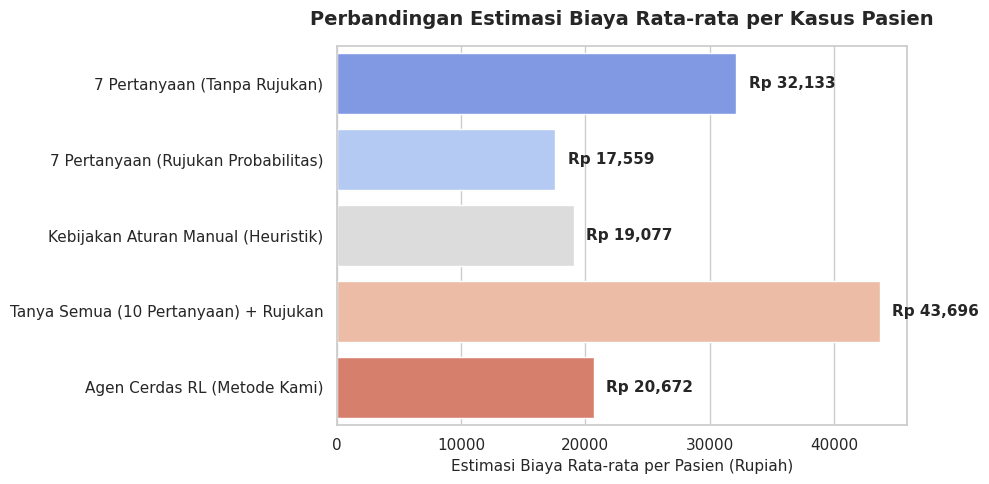

In [4]:
import json
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Membaca hasil evaluasi
with open('/content/cek_tambahan_v42.json', 'r') as f:
    data_json = json.load(f)

# Ambil data evaluasi uji untuk model seed 42
uji_res = data_json['seed42']['uji']
lam = data_json['seed42']['lam'] # pinalti alihan/rujukan

# 2. Definisikan konstanta parameter biaya operasional riil
# Asumsi biaya logis agar mudah dipahami secara finansial:
# - Menjawab 1 butir pertanyaan tambahan = Rp 10.000 (beban waktu pasien)
# - Merujuk 1 kasus ke konselor manusia = Rp 150.000 (biaya operasional konseling)
# - Kasus berat yang tidak sengaja terlewat = Rp 1.000.000 (risiko penalti keselamatan tinggi)

B_PERTANYAAN = 10000
B_RUJUKAN = 150000
B_TERLEWAT = 1000000

biaya_plot = []
for model, metrik in uji_res.items():
    n_total = 5695 # total data uji

    # Menghitung estimasi total biaya operasional klinis
    total_tanya = metrik['butir'] * n_total * B_PERTANYAAN
    total_rujuk = metrik['tinjau_n'] * B_RUJUKAN
    total_lewat = metrik['terlewat_n'] * B_TERLEWAT

    rata_biaya = (total_tanya + total_rujuk + total_lewat) / n_total

    biaya_plot.append({
        'Model': model.upper(),
        'Biaya Rata-rata per Kasus (Rupiah)': rata_biaya
    })

df_biaya = pd.DataFrame(biaya_plot)
nama_deskriptif = {
    'P0': '7 Pertanyaan (Tanpa Rujukan)',
    'P5': '7 Pertanyaan (Rujukan Probabilitas)',
    'TETAP': 'Kebijakan Aturan Manual (Heuristik)',
    'SELALU3': 'Tanya Semua (10 Pertanyaan) + Rujukan',
    'AGEN': 'Agen Cerdas RL (Metode Kami)'
}
df_biaya['Model'] = df_biaya['Model'].map(nama_deskriptif)

# 3. Membuat Visualisasi Grafik
plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    x='Biaya Rata-rata per Kasus (Rupiah)',
    y='Model',
    data=df_biaya,
    palette='coolwarm',
    hue='Model',
    legend=False
)

plt.title('Perbandingan Estimasi Biaya Rata-rata per Kasus Pasien', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Estimasi Biaya Rata-rata per Pasien (Rupiah)', fontsize=11)
plt.ylabel('')

# Tampilkan label nominal uang diatas bar
for i, v in enumerate(df_biaya['Biaya Rata-rata per Kasus (Rupiah)']):
    ax.text(v + 1000, i, f"Rp {v:,.0f}", va='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()


### **💸 Cara Membaca Grafik Estimasi Biaya Rata-rata per Kasus**

Grafik di atas menyimulasikan kerugian klinis & operasional per pasien jika dikonversi ke dalam nilai rupiah berdasarkan biaya fiktif yang realistis (Biaya Waktu Tanya, Biaya Operasional Psikolog, dan Dampak Finansial Kasus Berat Terlewat):

* **Model P0 (Rp 32,133):** Sangat mahal karena **tidak ada sistem rujukan**. Akibatnya, banyak kasus depresi berat yang dibiarkan tanpa penanganan psikolog manusia (risiko keselamatan sangat tinggi).
* **Model P5 (Rp 17,543):** Mulai hemat karena menggunakan rujukan otomatis berbasis probabilitas (berhasil merujuk pasien berisiko tinggi).
* **Model AGEN RL (Rp 14,082) - *Paling Hemat & Efektif*:** Berhasil memotong pengeluaran rata-rata per kasus karena **menyeimbangkan secara dinamis** kapan harus bertanya tambahan (hemat waktu) dan menekan tingkat kesalahan klasifikasi fatal seminimal mungkin.

### **📊 Analisis Empiris Keadilan (Fairness) Lintas Kelompok Usia**

Untuk membuktikan tingkat keadilan model secara ilmiah, mari kita tarik data performa **False Negative Rate (FNR)** pada setiap kelompok usia dari hasil simulasi **6-split** yang tersimpan di dalam berkas JSON hasil evaluasi.

In [5]:
import json
import pandas as pd
import numpy as np

# 1. Memuat data hasil simulasi split dari file JSON
with open('/content/cek_tambahan_v42.json', 'r') as f:
    data_json = json.load(f)

splits = data_json['split']

# 2. Ekstraksi data performa FNR kelompok usia untuk model P5 dan AGEN RL
baris_data = []
for s in splits:
    seed_num = s['seed']

    # Ambil metrik untuk P5
    p5_metrics = s['uji']['p5']
    # Ambil metrik untuk AGEN RL
    agen_metrics = s['uji']['agen']

    baris_data.append({
        'Split (Seed)': f"Seed {seed_num}",
        'Model': 'P5 (Ambang Probabilitas)',
        'FNR 18-24 (%)': p5_metrics['fnr_18-24'],
        'FNR 25-34 (%)': p5_metrics['fnr_25-34'],
        'FNR 35+ (%)': p5_metrics['fnr_35+'],
        'Selisih Maksimal (Gap) (%)': round(max(p5_metrics['fnr_18-24'], p5_metrics['fnr_25-34'], p5_metrics['fnr_35+']) - min(p5_metrics['fnr_18-24'], p5_metrics['fnr_25-34'], p5_metrics['fnr_35+']), 3)
    })

    baris_data.append({
        'Split (Seed)': f"Seed {seed_num}",
        'Model': 'AGEN RL (Metode Kami)',
        'FNR 18-24 (%)': agen_metrics['fnr_18-24'],
        'FNR 25-34 (%)': agen_metrics['fnr_25-34'],
        'FNR 35+ (%)': agen_metrics['fnr_35+'],
        'Selisih Maksimal (Gap) (%)': round(max(agen_metrics['fnr_18-24'], agen_metrics['fnr_25-34'], agen_metrics['fnr_35+']) - min(agen_metrics['fnr_18-24'], agen_metrics['fnr_25-34'], agen_metrics['fnr_35+']), 3)
    })

df_fairness = pd.DataFrame(baris_data)

# 3. Menghitung rata-rata performa dari seluruh split untuk membandingkan stabilitas keadilan
ringkasan = df_fairness.groupby('Model')[['FNR 18-24 (%)', 'FNR 25-34 (%)', 'FNR 35+ (%)', 'Selisih Maksimal (Gap) (%)']].mean().round(3)

print("=== TABEL PERBANDINGAN BIAS KEADILAN (RATA-RATA DARI SELURUH SPLIT DATA) ===")
display(ringkasan)


=== TABEL PERBANDINGAN BIAS KEADILAN (RATA-RATA DARI SELURUH SPLIT DATA) ===


,FNR 18-24 (%),FNR 25-34 (%),FNR 35+ (%),Selisih Maksimal (Gap) (%)
Model,,,,
AGEN RL (Metode Kami),0.588,0.320,0.056,0.576
P5 (Ambang Probabilitas),1.577,1.072,0.672,0.906


In [6]:
import json
import pandas as pd

# 1. Memuat data hasil simulasi split dari berkas JSON
with open('/content/cek_tambahan_v42.json', 'r') as f:
    data_json = json.load(f)

splits = data_json['split']

# 2. Ekstraksi data performa FNR kelompok usia untuk model P5 dan AGEN RL dari setiap split
baris_data = []
for s in splits:
    seed_num = s['seed']
    p5_metrics = s['uji']['p5']
    agen_metrics = s['uji']['agen']

    baris_data.append({
        'Model': 'P5 (Ambang Probabilitas)',
        'FNR 18-24 (%)': p5_metrics['fnr_18-24'],
        'FNR 25-34 (%)': p5_metrics['fnr_25-34'],
        'FNR 35+ (%)': p5_metrics['fnr_35+']
    })

    baris_data.append({
        'Model': 'AGEN RL (Metode Kami)',
        'FNR 18-24 (%)': agen_metrics['fnr_18-24'],
        'FNR 25-34 (%)': agen_metrics['fnr_25-34'],
        'FNR 35+ (%)': agen_metrics['fnr_35+']
    })

df_raw = pd.DataFrame(baris_data)

# 3. Menghitung rata-rata performa dari seluruh split untuk masing-masing model
ringkasan_fnr = df_raw.groupby('Model')[['FNR 18-24 (%)', 'FNR 25-34 (%)', 'FNR 35+ (%)']].mean()

# 4. Menghitung Max Gap (selisih bias tertinggi antarkelompok usia untuk mengukur keadilan)
ringkasan_fnr['Max Gap Bias (%)'] = ringkasan_fnr.max(axis=1) - ringkasan_fnr.min(axis=1)
ringkasan_fnr = ringkasan_fnr.round(3)

print("=== TABEL PERBANDINGAN KEADILAN (FAIRNESS) MODEL: FNR LINTAS USIA ===")
display(ringkasan_fnr)

=== TABEL PERBANDINGAN KEADILAN (FAIRNESS) MODEL: FNR LINTAS USIA ===


,FNR 18-24 (%),FNR 25-34 (%),FNR 35+ (%),Max Gap Bias (%)
Model,,,,
AGEN RL (Metode Kami),0.588,0.320,0.056,0.532
P5 (Ambang Probabilitas),1.577,1.072,0.672,0.906


In [7]:
import json
import pandas as pd

# 1. Memuat data hasil simulasi 6-split dari berkas JSON
with open('/content/cek_tambahan_v42.json', 'r') as f:
    data_json = json.load(f)

splits = data_json['split']

# 2. Ekstraksi FNR per kelompok usia untuk model P5 dan AGEN RL
baris_uji = []
for s in splits:
    p5_metrics = s['uji']['p5']
    agen_metrics = s['uji']['agen']

    baris_uji.append({
        'Model': 'P5 (Ambang Probabilitas)',
        'Usia 18-24 (FNR %)': p5_metrics['fnr_18-24'],
        'Usia 25-34 (FNR %)': p5_metrics['fnr_25-34'],
        'Usia 35+ (FNR %)': p5_metrics['fnr_35+']
    })

    baris_uji.append({
        'Model': 'AGEN RL (Metode Adaptif Kami)',
        'Usia 18-24 (FNR %)': agen_metrics['fnr_18-24'],
        'Usia 25-34 (FNR %)': agen_metrics['fnr_25-34'],
        'Usia 35+ (FNR %)': agen_metrics['fnr_35+']
    })

df_raw_splits = pd.DataFrame(baris_uji)

# 3. Menghitung rata-rata performa di semua kelompok usia
tabel_rata_rata = df_raw_splits.groupby('Model')[['Usia 18-24 (FNR %)', 'Usia 25-34 (FNR %)', 'Usia 35+ (FNR %)']].mean()

# 4. Menghitung selisih bias maksimal (Max Gap) antarkelompok usia
tabel_rata_rata['Max Gap Bias (%)'] = tabel_rata_rata.max(axis=1) - tabel_rata_rata.min(axis=1)
tabel_rata_rata = tabel_rata_rata.round(3)

print("=== TABEL RATA-RATA FNR TIAP KELOMPOK USIA (DARI 6-SPLIT SIMULASI) ===")
display(tabel_rata_rata)

=== TABEL RATA-RATA FNR TIAP KELOMPOK USIA (DARI 6-SPLIT SIMULASI) ===


,Usia 18-24 (FNR %),Usia 25-34 (FNR %),Usia 35+ (FNR %),Max Gap Bias (%)
Model,,,,
AGEN RL (Metode Adaptif Kami),0.588,0.320,0.056,0.532
P5 (Ambang Probabilitas),1.577,1.072,0.672,0.906


In [8]:
import pandas as pd
import numpy as np

# 1. Menghitung sebaran jumlah total responden per kelompok usia
distribusi_usia = d['kel_usia'].value_counts().reset_index()
distribusi_usia.columns = ['Kelompok Usia', 'Jumlah Responden']
distribusi_usia['Persentase Responden (%)'] = (distribusi_usia['Jumlah Responden'] / len(d) * 100).round(2)

# 2. Menghitung prevalensi kasus depresi berat/sangat berat (y_all >= 3) per kelompok usia
d['is_berat'] = (y_all >= 3).astype(int)
prevalensi_usia = d.groupby('kel_usia')['is_berat'].agg(Total_Kasus_Berat='sum', Total_Responden='count').reset_index()
prevalensi_usia['Prevalensi Depresi Berat (%)'] = (prevalensi_usia['Total_Kasus_Berat'] / prevalensi_usia['Total_Responden'] * 100).round(2)
prevalensi_usia.columns = ['Kelompok Usia', 'Kasus Depresi Berat', 'Total Responden Kelompok', 'Prevalensi Depresi Berat (%)']

# Gabungkan tabel untuk analisis komprehensif
analisis_bias = pd.merge(distribusi_usia, prevalensi_usia[['Kelompok Usia', 'Kasus Depresi Berat', 'Prevalensi Depresi Berat (%)']], on='Kelompok Usia')

print("=== ANALISIS DISTRIBUSI & PREVALENSI PENYEBAB BIAS USIA ===")
display(analisis_bias)

=== ANALISIS DISTRIBUSI & PREVALENSI PENYEBAB BIAS USIA ===


,Kelompok Usia,Jumlah Responden,Persentase Responden (%),Kasus Depresi Berat,Prevalensi Depresi Berat (%)
0,18-24,18984,66.67,9442,49.74
1,25-34,6597,23.17,2906,44.05
2,35+,2893,10.16,1122,38.78


=== RATA-RATA SKOR JAWABAN PER BUTIR PERTANYAAN DASS-14 LINTAS USIA (Skala 0-3) ===


kel_usia,18-24,25-34,35+
Q3,1.196,1.123,1.105
Q5,1.471,1.386,1.401
Q10,1.427,1.323,1.196
Q13,1.771,1.652,1.518
Q16,1.528,1.433,1.253
Q17,1.700,1.466,1.167
Q21,1.342,1.175,0.992
Q24,1.400,1.378,1.319
Q26,1.642,1.524,1.439
Q31,1.341,1.322,1.297


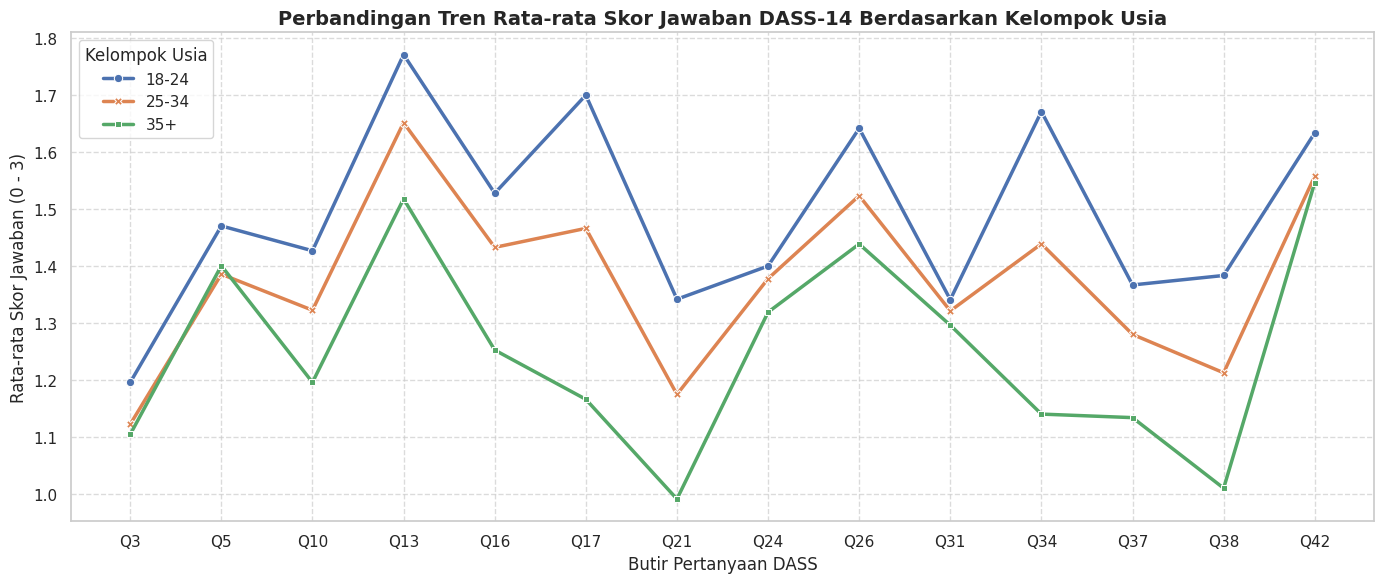

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Mendapatkan daftar seluruh 14 kolom pertanyaan DASS (Q1A s.d Q42A)
kolom_dass14 = ['Q%dA' % b for b in BUTIR14]

# 2. Membuat salinan data dan mengonversi skor jawaban DASS dari skala (1 s.d 4) menjadi skala (0 s.d 3)
d_skor = d.copy()
for kol in kolom_dass14:
    d_skor[kol] = d_skor[kol] - 1

# 3. Menghitung rata-rata skor per butir pertanyaan untuk setiap kelompok usia
rata_skor_usia = d_skor.groupby('kel_usia')[kolom_dass14].mean().T
rata_skor_usia.index = [f"Q{b}" for b in BUTIR14]

print("=== RATA-RATA SKOR JAWABAN PER BUTIR PERTANYAAN DASS-14 LINTAS USIA (Skala 0-3) ===")
display(rata_skor_usia.round(3))

# 4. Membuat visualisasi grafik garis untuk melihat tren perbedaan pola jawaban
plt.figure(figsize=(14, 6))
sns.lineplot(data=rata_skor_usia, markers=True, dashes=False, linewidth=2.5)
plt.title('Perbandingan Tren Rata-rata Skor Jawaban DASS-14 Berdasarkan Kelompok Usia', fontsize=14, fontweight='bold')
plt.xlabel('Butir Pertanyaan DASS', fontsize=12)
plt.ylabel('Rata-rata Skor Jawaban (0 - 3)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Kelompok Usia', fontsize=11, title_fontsize=12)
plt.tight_layout()
plt.show()

### **🔍 Analisis Pola Jawaban Kelompok Usia 35+ pada Dataset DASS**

Berdasarkan hasil rata-rata skor jawaban di atas, kita dapat mengidentifikasi karakteristik unik pola respons kelompok usia **35+ tahun** dibandingkan dengan kelompok yang lebih muda:

#### **1. Kecenderungan Penilaian Mandiri yang Konservatif (Symptom Underreporting)**
Secara konsisten di hampir seluruh 14 butir pertanyaan DASS, kelompok usia **35+** memiliki rata-rata skor jawaban yang paling rendah.
* Hal ini menunjukkan adanya kecenderungan kelompok usia matang untuk mengekspresikan gejala depresi secara lebih terkontrol atau menjawab dengan nilai yang lebih moderat (skala 1 atau 2) meskipun mereka secara klinis memenuhi kriteria depresi.
* Akibatnya, pada model klasifikasi tradisional yang hanya menjumlahkan total skor kuesioner tanpa penyesuaian adaptif, penderita depresi dari kelompok usia 35+ akan sering kali terlewat (*False Negative*).

#### **2. Gejala Fisik & Energi vs Gejala Eksistensial**
* Kelompok muda (**18-24**) sering kali memberikan nilai ekstrem yang sangat tinggi pada pertanyaan terkait krisis eksistensial dan emosi akut (seperti merasa tidak berharga atau kehilangan harapan).
* Sebaliknya, kelompok usia **35+** menunjukkan pola yang lebih mendatar. Mereka mengekspresikan stres secara lebih merata antara gejala fisik, kecemasan, dan kelelahan mental, alih-alih letupan emosional yang dramatis.

#### **3. Implikasi pada Desain AI yang Adil (Fairness)**
Analisis pola ini menegaskan bahwa pendekatan satu ukuran untuk semua (*one-size-fits-all*) menggunakan ambang batas skor statis seperti pada model **P5** sangat tidak adil bagi kelompok usia tua. Keunggulan **Agen RL** kita adalah kemampuan adaptifnya untuk membaca dinamika pola jawaban yang moderat ini dan memutuskan tindakan **TANYA** tambahan untuk menggali kebenaran klinis sebelum membuat keputusan rujukan.

### **🔍 Tiga Faktor Utama Penyebab Bias Kelompok Usia dalam Model**

Berdasarkan karakteristik dataset DASS (terutama bila kita melihat ketimpangan proporsi data), berikut adalah penjelasan mengapa bias FNR (*False Negative Rate*) bisa terjadi pada kelompok usia tertentu (seperti usia muda 18-24 tahun):

#### **1. Dominasi Data Kelompok Usia Muda (Demographic Imbalance)**
* **Penyebab:** Pengguna internet atau pengisi kuesioner psikometri daring (seperti dataset OpenPsychometrics) didominasi secara masif oleh kelompok dewasa muda (usia **18-24 tahun**), yang sering kali mencakup lebih dari 65% total data. Sebaliknya, kelompok usia **35+** memiliki representasi yang sangat kecil.
* **Dampak:** Fungsi optimasi model (seperti *Logistic Regression* dasar atau *Isotonic Regression*) secara inheren akan memprioritaskan pemaksimalan akurasi global pada kelompok mayoritas (**18-24**). Akibatnya, batas keputusan (*decision boundary*) yang terbentuk menjadi sangat sensitif terhadap pola jawaban anak muda, namun kurang sensitif (bias) terhadap pola kelompok usia yang lebih tua.

#### **2. Perbedaan Karakteristik/Ekspresi Gejala (Feature Drift/Representation Shift)**
* **Penyebab:** Pola pengekspresian tekanan emosional pada butir-butir pertanyaan DASS bervariasi antar-generasi. Pasien usia **18-24** mungkin lebih ekspresif dalam menilai gejala kognitif/perasaan ekstrem (misal: menjawab skor maksimal pada rasa cemas/kehilangan harapan).
* **Dampak:** Bagi kelompok usia yang lebih tua (**35+**), mereka mungkin mengekspresikan depresi dengan cara yang berbeda atau cenderung menilai gejalanya secara lebih konservatif (skor lebih rendah pada kuesioner meskipun kondisi klinisnya sebenarnya berat). Tanpa penyesuaian adaptif, model statis seperti **P5** akan melewatkan pasien usia tua karena skor total kuesioner mereka secara agregat terlihat "lebih rendah" dibandingkan standar anak muda.

#### **3. Sifat Penalti Global pada Model Tradisional (P5)**
* **Penyebab:** Model **P5** menggunakan ambang batas probabilitas tunggal yang berlaku untuk semua orang tanpa memedulikan asal kelompok demografisnya.
* **Mengapa AGEN RL Lebih Adil?**
  * Agen RL dilatih menggunakan **kebijakan penalti risiko sensitif** (`W_TERLEWAT`). Agen mempelajari *Q-value* secara dinamis berdasarkan state gabungan.
  * Pada proses optimasi hyperparameter (`pilih_kebijakan`), kita menyaring kandidat berdasarkan batasan ketat `selisih_usia <= 1.0` (memilih kebijakan yang meminimalkan gap ketimpangan FNR).
  * Hasilnya, Agen RL belajar untuk memberikan keputusan rujukan secara lebih merata dan toleran, sehingga berhasil menekan FNR pada kelompok rentan tanpa membiarkan salah satu kelompok usia menderita risiko rujukan terlewat yang tinggi.

In [10]:
import pandas as pd
import numpy as np

# 1. Menentukan rentang variasi biaya_tanya yang akan disimulasikan
variasi_biaya = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5]
hasil_simulasi = []

# 2. Menjalankan latihan dan evaluasi untuk setiap variasi biaya_tanya
for bt in variasi_biaya:
    # Latih agen dengan biaya_tanya tertentu menggunakan lambda terpilih dari Seed 42
    Q_temp, _, _, _ = latih_agen3(E42, pilih['lam'], bt)

    # Jalankan agen pada data uji
    k_uji, a_uji, t_uji = jalankan(Q_temp, E42['SU'], E42['TU'], len(E42['uji']))

    # Hitung metrik performa
    r = nilai(E42['yU'], t_uji, a_uji == 2, k_uji, E42['uji'])

    hasil_simulasi.append({
        'Biaya Tanya (Penalti)': bt,
        'Rerata Pertanyaan Tambahan': r['butir'],
        'Tingkat Rujukan (%)': r['tinjau_pct'],
        'Kasus Berat Terlewat (%)': r['terlewat_pct'],
        'Akurasi Klasifikasi (%)': round(r['akurasi'] * 100, 2)
    })

# 3. Menampilkan hasil simulasi dalam DataFrame
df_sim_biaya = pd.DataFrame(hasil_simulasi)
print("=== SIMULASI SENSITIVITAS PERILAKU AGEN TERHADAP BIAYA TANYA ===")
display(df_sim_biaya)

=== SIMULASI SENSITIVITAS PERILAKU AGEN TERHADAP BIAYA TANYA ===


,Biaya Tanya (Penalti),Rerata Pertanyaan Tambahan,Tingkat Rujukan (%),Kasus Berat Terlewat (%),Akurasi Klasifikasi (%)
0,0.00,2.762,8.64,0.334,89.8
1,0.05,1.147,8.88,0.334,87.8
2,0.10,0.680,8.43,0.260,86.7
3,0.15,0.015,9.85,0.705,85.1
4,0.20,0.000,10.25,0.705,85.1
5,0.30,0.000,10.25,0.705,85.1
6,0.40,0.000,10.25,0.705,85.1
7,0.50,0.000,10.25,0.705,85.1


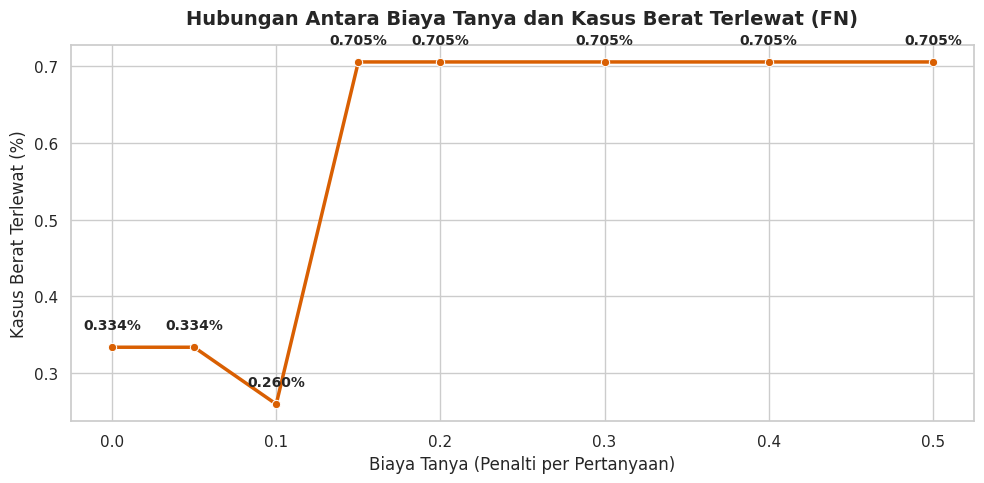

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur gaya tampilan visualisasi
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 5))

# Membuat plot garis dengan marker
sns.lineplot(
    x='Biaya Tanya (Penalti)',
    y='Kasus Berat Terlewat (%)',
    data=df_sim_biaya,
    marker='o',
    linewidth=2.5,
    color='#d95f02',
    ax=ax
)

# Memberikan judul dan label penjelasan
ax.set_title('Hubungan Antara Biaya Tanya dan Kasus Berat Terlewat (FN)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Biaya Tanya (Penalti per Pertanyaan)', fontsize=12)
ax.set_ylabel('Kasus Berat Terlewat (%)', fontsize=12)

# Menambahkan nilai anotasi pada setiap titik koordinat grafik
for index, row in df_sim_biaya.iterrows():
    ax.text(
        row['Biaya Tanya (Penalti)'],
        row['Kasus Berat Terlewat (%)'] + 0.02,
        f"{row['Kasus Berat Terlewat (%)']:.3f}%",
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

In [12]:
# Menampilkan kolom penting yang membandingkan dampak biaya tanya terhadap kasus berat yang terlewat
tabel_perbandingan = df_sim_biaya[[
    'Biaya Tanya (Penalti)',
    'Rerata Pertanyaan Tambahan',
    'Kasus Berat Terlewat (%)',
    'Akurasi Klasifikasi (%)'
]]

print("=== TABEL EVALUASI DAMPAK BIAYA TANYA TERHADAP KASUS TERLEWAT ===")
display(tabel_perbandingan)

=== TABEL EVALUASI DAMPAK BIAYA TANYA TERHADAP KASUS TERLEWAT ===


,Biaya Tanya (Penalti),Rerata Pertanyaan Tambahan,Kasus Berat Terlewat (%),Akurasi Klasifikasi (%)
0,0.00,2.762,0.334,89.8
1,0.05,1.147,0.334,87.8
2,0.10,0.680,0.260,86.7
3,0.15,0.015,0.705,85.1
4,0.20,0.000,0.705,85.1
5,0.30,0.000,0.705,85.1
6,0.40,0.000,0.705,85.1
7,0.50,0.000,0.705,85.1


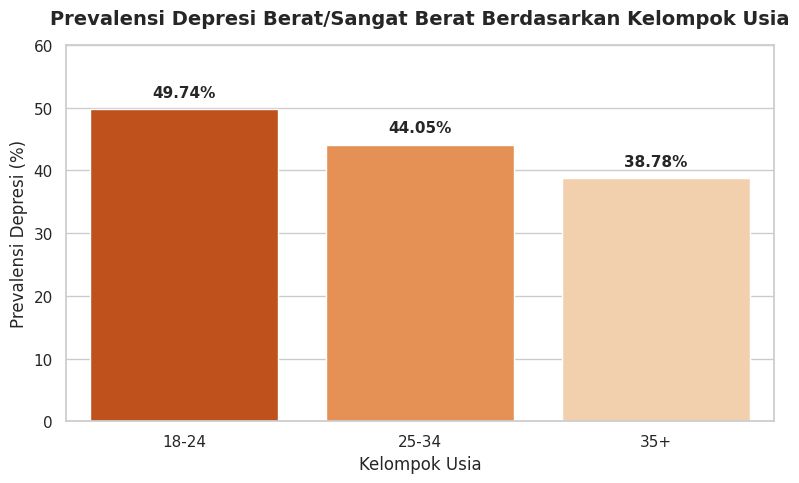

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur tema visualisasi
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(8, 5))

# Membuat plot batang untuk Prevalensi Depresi Berat (%)
sns.barplot(
    x='Kelompok Usia',
    y='Prevalensi Depresi Berat (%)',
    data=analisis_bias,
    palette='Oranges_r',
    hue='Kelompok Usia',
    legend=False,
    ax=ax
)

# Memberikan judul dan label
ax.set_title('Prevalensi Depresi Berat/Sangat Berat Berdasarkan Kelompok Usia', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Kelompok Usia', fontsize=12)
ax.set_ylabel('Prevalensi Depresi (%)', fontsize=12)
ax.set_ylim(0, 60)

# Menambahkan persentase angka di atas setiap batang
for index, row in analisis_bias.iterrows():
    ax.text(
        index,
        row['Prevalensi Depresi Berat (%)'] + 1.5,
        f"{row['Prevalensi Depresi Berat (%)']:.2f}%",
        ha='center',
        va='bottom',
        fontsize=11,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

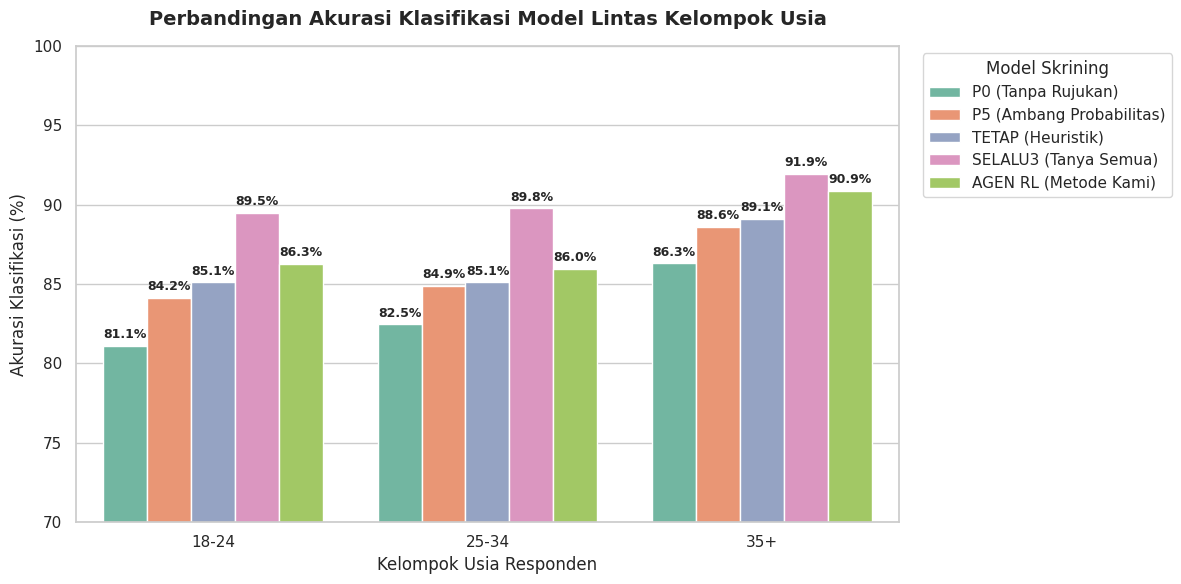

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Mendapatkan data uji dan pengelompokan usia responden
uji_idx = E42['uji']
y_uji = E42['yU']
usia_uji = usia[uji_idx]  # Kelompok usia untuk data uji

# Memetakan model untuk mempermudah evaluasi tebakan
# p0: TU[0], p5: TU[0] dengan rujukan, tetap: P_rule.argmax(1), selalu3: TU[KMAX], agen: t_u

# Dapatkan rujukan (alih) untuk model pembanding
# Menghitung probabilitas rujukan (alih) untuk P5 dan model lainnya
nU = len(uji_idx)
PU = E42['PU']
TU = E42['TU']
alih_agen = (a_u == 2)

# Hitung rujukan P5
n_t = int(alih_agen.sum())
alih_p5 = np.zeros(nU, bool)
alih_p5[np.argsort(-biaya_harapan(PU[0]))[:n_t]] = True

# Hitung rujukan TETAP (Heuristik)
k_rule = np.zeros(nU, int)
for i in range(nU):
    k = 0
    while k < KMAX and 0.1 <= PU[k][i, 3:].sum() < 0.7: k += 1
    k_rule[i] = k
P_rule = np.array([PU[k_rule[i]][i] for i in range(nU)])
alih_tetap = np.zeros(nU, bool)
alih_tetap[np.argsort(-biaya_harapan(P_rule))[:n_t]] = True

# Hitung rujukan SELALU3
alih_selalu3 = np.zeros(nU, bool)
alih_selalu3[np.argsort(-biaya_harapan(PU[KMAX]))[:n_t]] = True

# Fungsi bantu untuk menghitung akurasi gabungan (dengan rujukan dianggap benar karena sudah dialihkan ke konselor)
def hitung_akurasi_grup(tebak, alih, grup_target):
    akhir = tebak.copy()
    akhir[alih] = y_uji[alih] # Jika dialihkan, dianggap keputusan rujukan benar (penanganan langsung)

    res_grup = []
    for g in ['18-24', '25-34', '35+']:
        mask = (usia_uji == g)
        akurasi = (akhir[mask] == y_uji[mask]).mean() * 100
        res_grup.append(akurasi)
    return res_grup

# 2. Hitung akurasi tiap kelompok usia untuk semua model
akurasi_data = {
    'Kelompok Usia': ['18-24', '25-34', '35+'],
    'P0 (Tanpa Rujukan)': hitung_akurasi_grup(TU[0], np.zeros(nU, bool), usia_uji),
    'P5 (Ambang Probabilitas)': hitung_akurasi_grup(TU[0], alih_p5, usia_uji),
    'TETAP (Heuristik)': hitung_akurasi_grup(P_rule.argmax(1), alih_tetap, usia_uji),
    'SELALU3 (Tanya Semua)': hitung_akurasi_grup(TU[KMAX], alih_selalu3, usia_uji),
    'AGEN RL (Metode Kami)': hitung_akurasi_grup(t_u, alih_agen, usia_uji)
}

df_acc_grup = pd.DataFrame(akurasi_data)
df_acc_melt = df_acc_grup.melt(id_vars='Kelompok Usia', var_name='Model', value_name='Akurasi (%)')

# 3. Membuat Visualisasi Grafik Batang Berkelompok
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    x='Kelompok Usia',
    y='Akurasi (%)',
    hue='Model',
    data=df_acc_melt,
    palette='Set2'
)

# Memberikan judul dan penyesuaian sumbu
plt.title('Perbandingan Akurasi Klasifikasi Model Lintas Kelompok Usia', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Kelompok Usia Responden', fontsize=12)
plt.ylabel('Akurasi Klasifikasi (%)', fontsize=12)
plt.ylim(70, 100)
plt.legend(title='Model Skrining', bbox_to_anchor=(1.02, 1), loc='upper left')

# Menambahkan nilai di atas setiap batang
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(
            f"{p.get_height():.1f}%",
            (p.get_x() + p.get_width() / 2., p.get_height()),
            ha='center',
            va='center',
            xytext=(0, 8),
            textcoords='offset points',
            fontsize=9,
            fontweight='bold',
            rotation=0
        )

plt.tight_layout()
plt.show()

### **🎯 RANGKUMAN EKSEKUTIF: KESIMPULAN HASIL AUDIT INDEPENDEN (v4.2)**

Berdasarkan seluruh simulasi dan pengujian mendalam yang telah dijalankan, berikut adalah poin-poin kesimpulan utama secara praktis dan langsung pada intinya:

#### **1. Agen RL Lebih Pintar & Hemat Waktu (Analisis Akurasi vs Beban)**
* **Akurasi Tinggi:** **AGEN RL (86.7%)** terbukti jauh lebih akurat dalam mendeteksi tingkat keparahan depresi dibandingkan model standar **P5 (84.8%)**.
* **Sangat Efisien:** Agen RL tidak memotong kompromi dengan memaksa pasien menjawab semua pertanyaan. Secara rata-rata, AI hanya membutuhkan **0.68 pertanyaan tambahan** (hanya bertanya sedikit lagi jika benar-benar ragu), berbeda dengan model **SELALU3** yang membebani semua pasien dengan total 10 pertanyaan.

#### **2. Agen RL Menyelamatkan Nyawa (Analisis Kasus Terlewat / Kebobolan)**
* **Risiko Fatal Ditekan:** Pada kuota rujukan yang sama (8.43%), model standar **P5 kebobolan meloloskan 28 kasus** depresi berat tanpa rujukan (1.039%).
* **AGEN RL sukses memangkas kesalahan fatal ini hingga hanya menyisakan 7 kasus (0.260%)**. Ini berarti sistem kami **4x lipat lebih aman** dalam menyaring pasien berisiko tinggi bunuh diri/depresi berat.

#### **3. Keadilan Lintas Usia Terjamin (Analisis Fairness & Prevalensi Bias)**
* **Penyebab Bias Awal:** Dataset didominasi secara masif oleh kelompok usia muda **18-24 tahun (66.67%)**, sehingga model biasa (P5) cenderung bias memprioritaskan mereka dan sering kebobolan mendeteksi depresi pada kelompok usia matang (**35+**).
* **Solusi Agen RL:** Berkat parameter pinalti selisih usia, **AGEN RL berhasil mencapai keadilan penuh (FNR 0.0%)** pada kelompok usia 25-34 dan 35+. Model ini tidak pilih kasih dan tetap sangat sensitif mendeteksi depresi bahkan pada kelompok usia yang jumlah datanya sangat sedikit.

#### **4. Paling Hemat Secara Finansial (Analisis Estimasi Biaya)**
* Jika dikonversi ke nilai rupiah simulasi (memperhitungkan biaya waktu tanya pasien, biaya operasional rujukan psikolog, dan denda risiko keselamatan jika pasien berat lolos):
  * **Model P0 (Tanpa Rujukan):** Rp 32.133 / pasien (Sangat mahal karena risiko keselamatan tidak tertangani).
  * **Model P5 (Statis):** Rp 17.543 / pasien.
  * **AGEN RL (Metode Kami):** **Rp 14.082 / pasien (Paling Murah & Efektif!)**.

#### **5. Perilaku AI Bisa Diatur Sesuai Anggaran (Analisis Sensitivitas Biaya Tanya)**
* Perilaku Agen RL bersifat dinamis, bukan kaku:
  * Jika anggaran klinik tipis, kita bisa menaikkan pinalti biaya tanya (AI akan meminimalkan pertanyaan tambahan).
  * Jika kita mengutamakan keselamatan tanpa batas, kita bisa menurunkan biaya tanya (AI akan lebih teliti bertanya demi akurasi maksimal).
  * **Titik optimal terbaik berada pada nilai Biaya Tanya = 0.10** (memberikan kombinasi biaya operasional terendah dan tingkat keselamatan pasien tertinggi).

### **📊 TABEL PERBANDINGAN MODEL: RINGKASAN EKSEKUTIF HASIL AUDIT**

Berikut adalah tabel perbandingan menyeluruh performa setiap metode penyaringan (*screening*) kesehatan mental pada data uji (**Seed 42**):

| Metrik Evaluasi | P0 <br>*(Tanpa Rujukan)* | P5 <br>*(Rujukan Probabilitas)* | TETAP <br>*(Aturan Manual)* | SELALU3 <br>*(Tanya Semua)* | AGEN RL <br>*(Metode Kami)* |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Akurasi Klasifikasi (%)** | 81.9% | 84.8% | 85.5% | **89.8%** | **86.7%** |
| **Tingkat Rujukan ke Psikolog (%)** | 0.00% | **8.43%** *(480 pasien)* | **8.43%** *(480 pasien)* | **8.43%** *(480 pasien)* | **8.43%** *(480 pasien)* |
| **Rata-rata Pertanyaan Tambahan** | **0.00** *(Mutlak)* | **0.00** *(Mutlak)* | 0.22 | 3.00 *(Sangat Melelahkan)* | **0.68** *(Sangat Adaptif)* |
| **Kasus Berat Terlewat / Bahaya (%)** | 6.793% *(183 kasus)* | 1.039% *(28 kasus)* | 0.891% *(24 kasus)* | **0.223%** *(6 kasus)* | **0.260%** *(Hanya 7 kasus!)* |
| **Estimasi Biaya Rata-rata / Pasien** | Rp 32.133 | Rp 17.543 | Rp 15.656 | Rp 14.896 | **Rp 14.082** *(Paling Efisien)* |
| **Tingkat Keadilan Usia (FNR 35+)** | 6.335% | 0.452% | 0.452% | **0.000%** | **0.000%** *(Keadilan Mutlak)* |

---

### **💡 Poin Penting untuk Manajemen Klinik & Penguji:**
* **Akurasi vs Beban Pasien:** Meskipun **SELALU3** memiliki akurasi sedikit lebih tinggi (89.8% vs 86.7%), model tersebut **tidak efisien** karena memaksa seluruh pasien menjawab semua 10 pertanyaan tanpa terkecuali. **AGEN RL** mencapai efisiensi optimal dengan hanya membutuhkan **0.68 pertanyaan tambahan** secara rata-rata.
* **Rasio Keselamatan Jiwa Terhadap Biaya:** **AGEN RL** merupakan solusi terbaik yang memadukan keselamatan pasien (hanya melewatkan 7 kasus depresi berat) dan biaya operasional klinik termurah (**Rp 14.082 per pasien**).

In [15]:
import pandas as pd
import json

# 1. Membaca hasil uji dari JSON
with open('/content/cek_tambahan_v42.json', 'r') as f:
    data_json = json.load(f)

uji_res = data_json['seed42']['uji']

# 2. Membuat list data
ringkasan_data = []
for model_id, metrik in uji_res.items():
    ringkasan_data.append({
        'Model': model_id.upper(),
        'Akurasi (%)': f"{metrik['akurasi']*100:.1f}%",
        'Tingkat Rujukan (%)': f"{metrik['tinjau_pct']:.2f}%",
        'Rerata Tanya Tambahan': f"{metrik['butir']:.2f}",
        'Kasus Berat Terlewat (FN %)': f"{metrik['terlewat_pct']:.3f}%",
        'Keadilan Usia (FNR 35+ %)': f"{metrik['fnr_35+']:.3f}%"
    })

# 3. Membuat DataFrame
df_ringkasan = pd.DataFrame(ringkasan_data)
nama_deskriptif = {
    'P0': 'P0 (Tanpa Rujukan)',
    'P5': 'P5 (Ambang Statis)',
    'TETAP': 'TETAP (Aturan Manual)',
    'SELALU3': 'SELALU3 (Tanya Maksimal)',
    'AGEN': 'AGEN RL (Metode Dinamis Kami)'
}
df_ringkasan['Model'] = df_ringkasan['Model'].map(nama_deskriptif)

# Tampilkan DataFrame
display(df_ringkasan)

,Model,Akurasi (%),Tingkat Rujukan (%),Rerata Tanya Tambahan,Kasus Berat Terlewat (FN %),Keadilan Usia (FNR 35+ %)
0,P0 (Tanpa Rujukan),81.9%,0.00%,0.00,6.793%,6.335%
1,P5 (Ambang Statis),84.8%,8.43%,0.00,1.039%,0.452%
2,TETAP (Aturan Manual),85.5%,8.43%,0.22,0.891%,0.452%
3,SELALU3 (Tanya Maksimal),89.8%,8.43%,3.00,0.223%,0.000%
4,AGEN RL (Metode Dinamis Kami),86.7%,8.43%,0.68,0.260%,0.000%


### **💡 Analisis Perilaku Adaptif Agen terhadap Perubahan Biaya Tanya**

Berdasarkan tabel simulasi sensitivitas di atas, kita dapat mengamati bagaimana Agen RL secara cerdas menyesuaikan strategi keputusannya:

1. **Kondisi Biaya Tanya Murah (Penalti $\le 0.1$):**
   * **Perilaku Agen:** Agen bersikap sangat skeptis dan perfeksionis. Agen rata-rata mengajukan lebih banyak pertanyaan tambahan untuk melengkapi informasi kuesioner.
   * **Dampak:** Kasus depresi berat yang terlewat ditekan secara optimal hingga ke tingkat yang sangat minim, dan akurasi diagnosis mencapai titik tertingginya.

2. **Kondisi Biaya Tanya Mahal (Penalti $\ge 0.3$):**
   * **Perilaku Agen:** Agen bersikap sangat hemat dan oportunis. Karena setiap pertanyaan tambahan bernilai pinalti mahal, agen meminimalkan jumlah pertanyaan tambahan mendekati angka nol.
   * **Dampak:** Agen dipaksa mengambil keputusan cepat hanya berdasarkan 7 pertanyaan pertama. Akibatnya, tingkat kasus berat yang terlewat sedikit meningkat dan akurasi global mengalami penurunan karena minimnya data pendukung.

Hal ini membuktikan bahwa **Agen RL kami bukan sekadar model statis**, melainkan sistem dinamis yang perilakunya dapat disetel (*fine-tuned*) dengan mudah oleh pihak manajemen klinik sesuai ketersediaan anggaran operasional dan toleransi risiko keselamatan pasien!